In [80]:
import cv2
import matplotlib.pyplot as plt 
import numpy as np
import random

In [81]:
def show_img_plt(img, c_map ='gray', fig_hight=8, fig_width=6, vmin=0, vmax=255):
    plt.figure(figsize=(fig_hight, fig_width), dpi=100)
    plt.imshow(img, cmap=c_map, vmin=vmin, vmax=vmax)

In [82]:
def show_mult_img(rows, columns, img_names, vmin=0, vmax=255):
    fig = plt.figure(figsize=(15, 17), dpi=100)
    for i in range(len(img_names)):
        fig.add_subplot(rows, columns, i+1)
        plt.imshow(img_names[i], cmap='gray', vmin=vmin, vmax=vmax)
        plt.axis('off')
        plt.title('img_' + str(i))

In [83]:
#Load images
image = cv2.imread(r'img/color_1.jpg', cv2.IMREAD_UNCHANGED)
image_color = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)
image_gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)

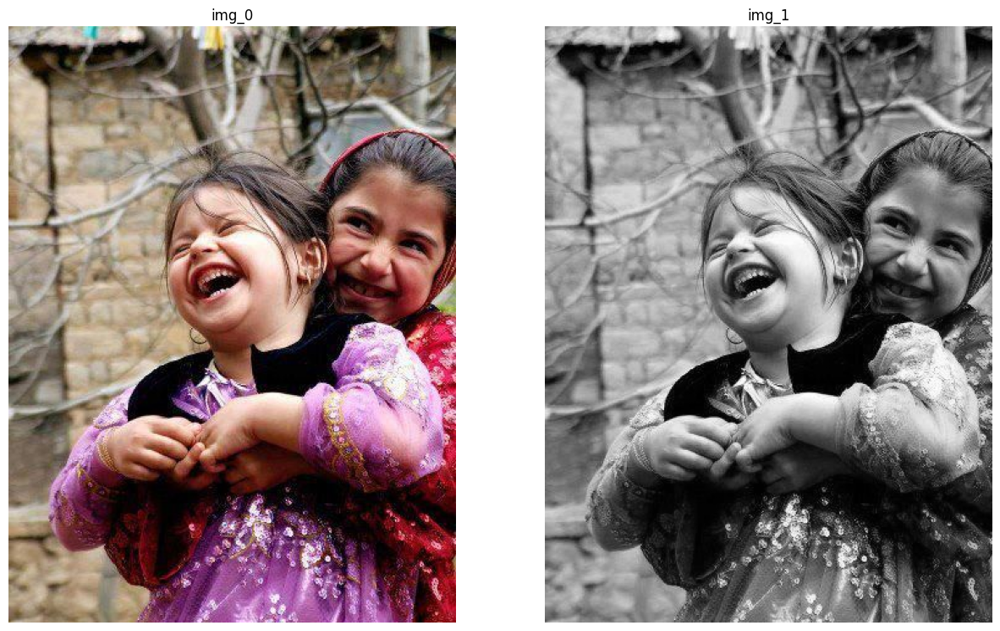

In [84]:
show_mult_img(1, 2, (image_color, image_gray))

In [87]:
#add gaussian noise!
def add_gaussian_noise(img, mean=0, variance=100):
    image = img.copy()
    gaussian = np.zeros(image.shape, np.uint8)
    cv2.randn(gaussian, mean, variance)
    return cv2.add(image, gaussian)
    

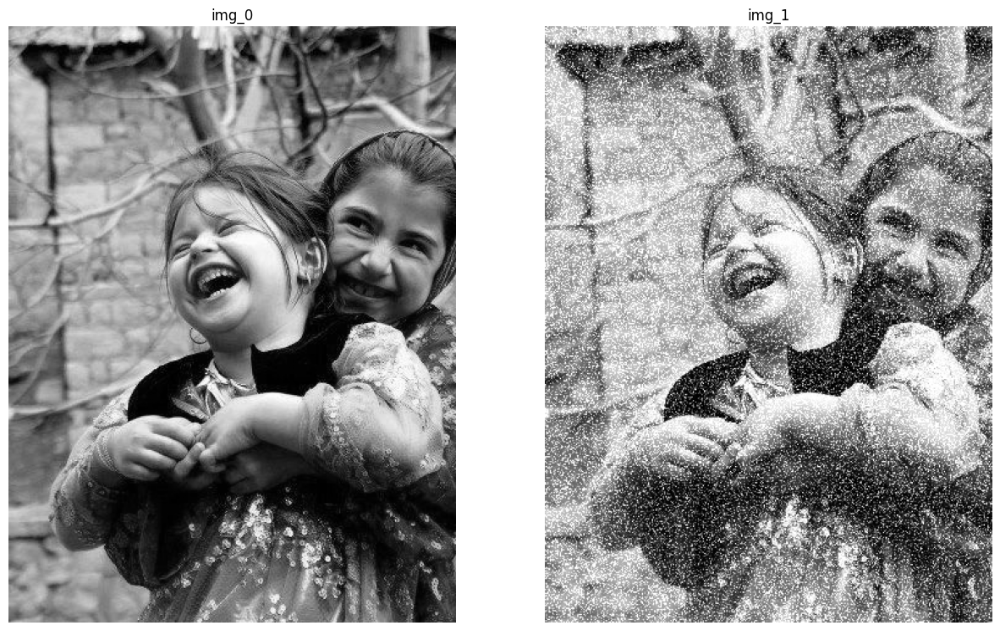

In [88]:
gaus_noise_gray_img = add_gaussian_noise(image_gray)
show_mult_img(1, 2, (image_gray, gaus_noise_gray_img))

In [89]:
#add salt and pepper
def add_salt_pepper_noise(img, threshold):
    image = img.copy()
    numPixels = image.shape[0]*image.shape[1]
    numNoise = numPixels*threshold
    
    for i in range(0, image.shape[0]):
        for j in range(0, image.shape[1]):
            randNum = random.randint(0, numPixels)
            
            if randNum < numNoise:
                image[i, j] = random.randint(0, 1)*255
    return image        

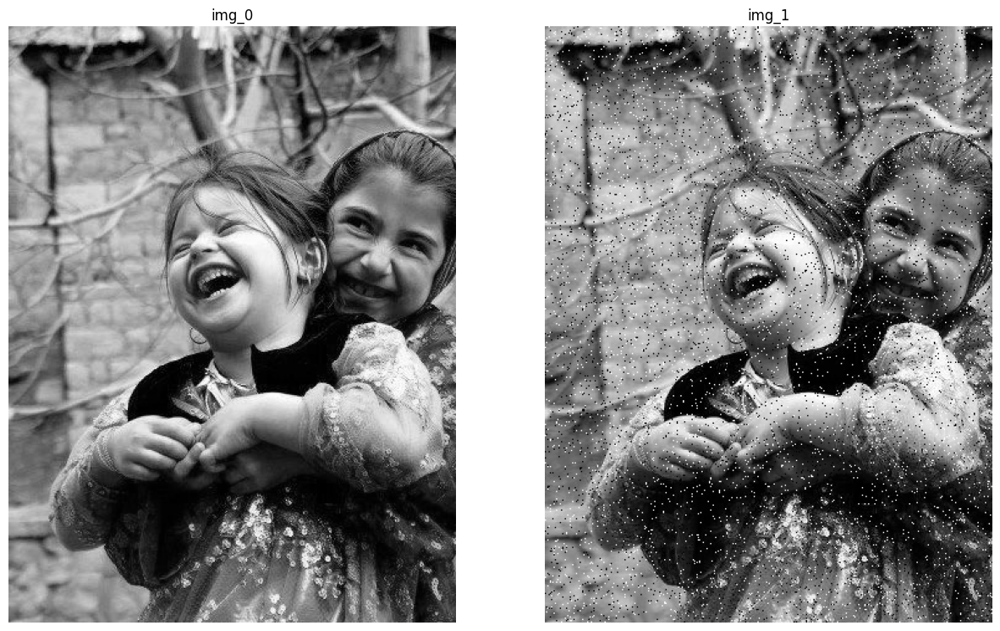

In [90]:
salt_pepper_noise_gray_img = add_salt_pepper_noise(image_gray, 0.05)
show_mult_img(1, 2, (image_gray, salt_pepper_noise_gray_img))

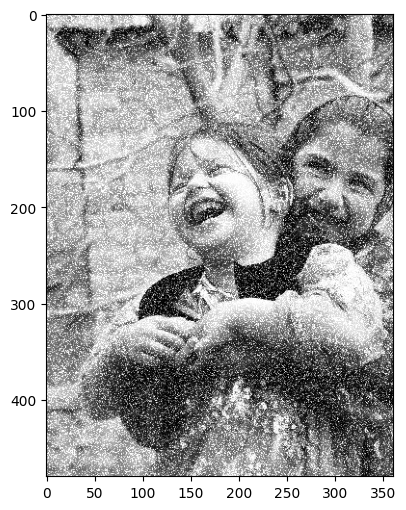

In [94]:
kernel = np.array([[0, 0, 0], 
                  [0, 1, 0], 
                  [0, 0, 0]])

gaus_noise_gray_img_2 = gaus_noise_gray_img.copy()
convolved_img = cv2.filter2D(src=gaus_noise_gray_img_2,ddepth=-1, kernel=kernel)
show_img_plt(convolved_img)

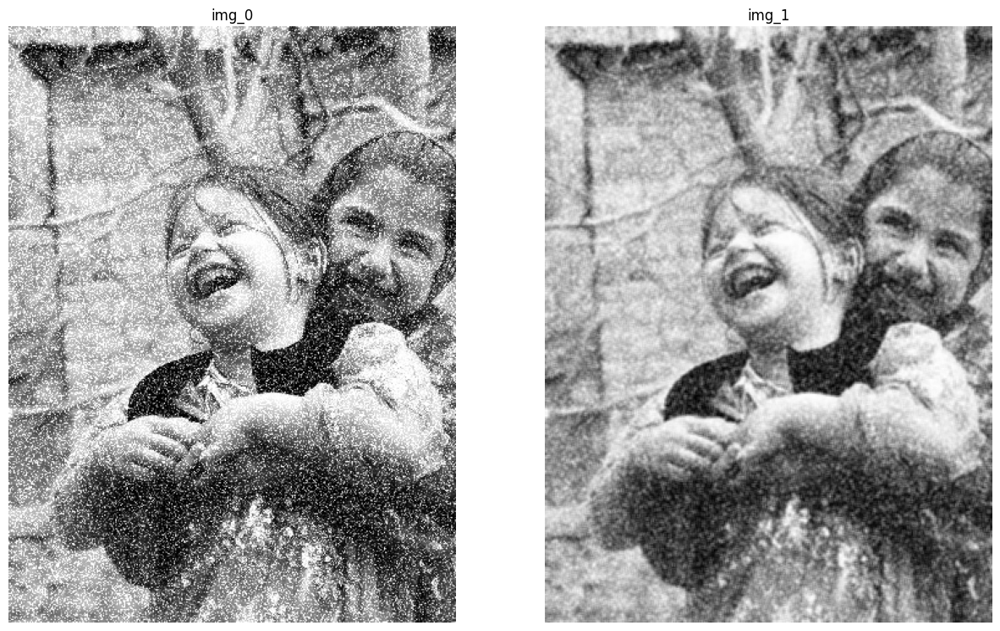

In [95]:
#Box filter
gaus_noise_gray_img_3 = gaus_noise_gray_img.copy()
box_gaussian_img = cv2.blur(gaus_noise_gray_img_3, (3, 3))
show_mult_img(1, 2, (gaus_noise_gray_img, box_gaussian_img))

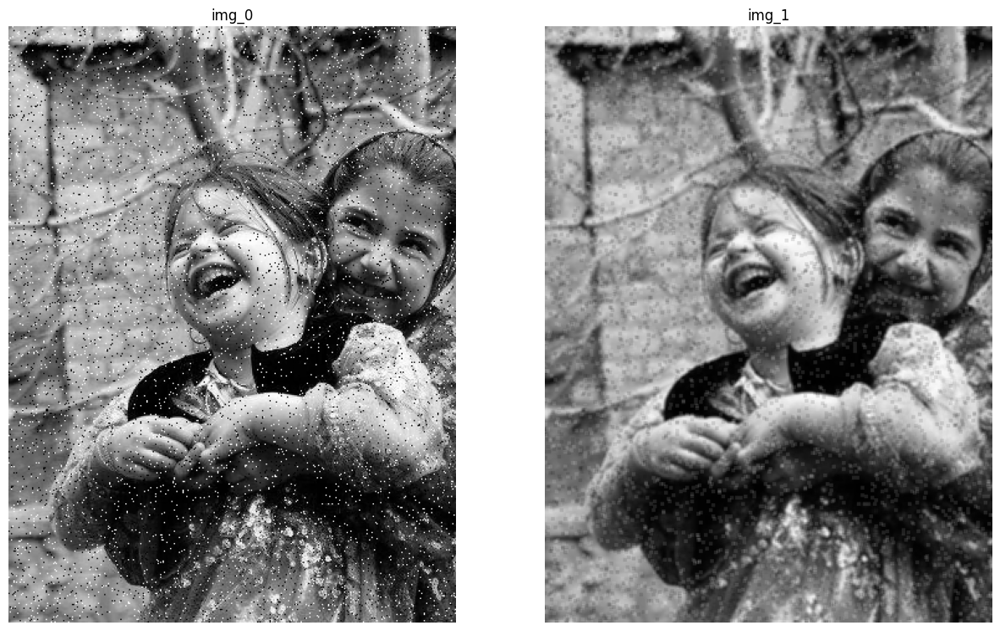

In [96]:
salt_pepper_noise_gray_img_2 = salt_pepper_noise_gray_img.copy()
box_salpep_img = cv2.blur(salt_pepper_noise_gray_img_2, (3, 3))
show_mult_img(1, 2, (salt_pepper_noise_gray_img, box_salpep_img))

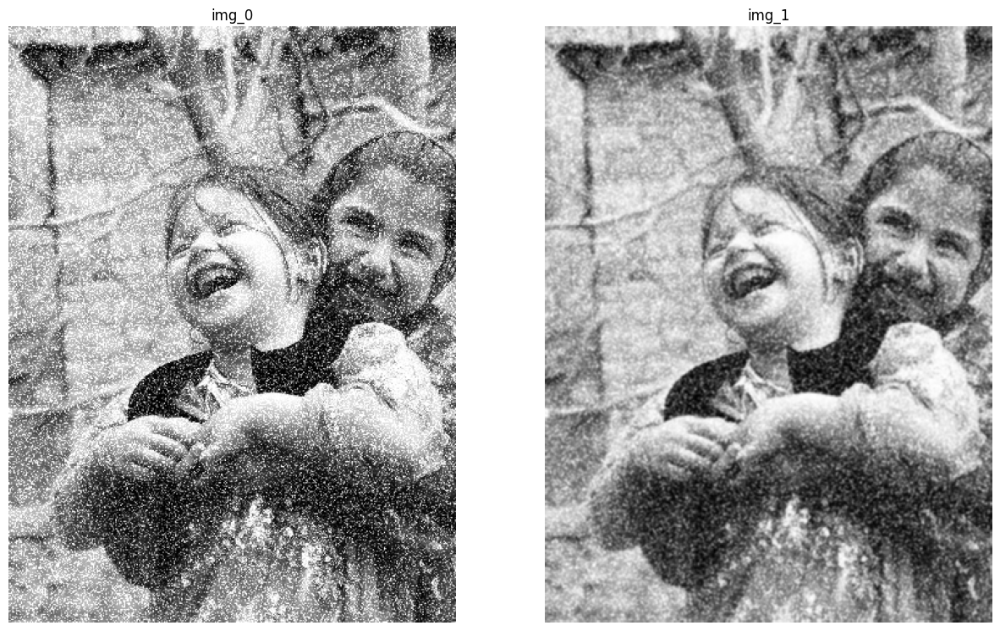

In [97]:
#Gaussian filter
gaus_noise_gray_img_4 = gaus_noise_gray_img.copy()
gauss_gauss_img = cv2.GaussianBlur(gaus_noise_gray_img_4, (3, 3),0)
show_mult_img(1, 2, (gaus_noise_gray_img, gauss_gauss_img))

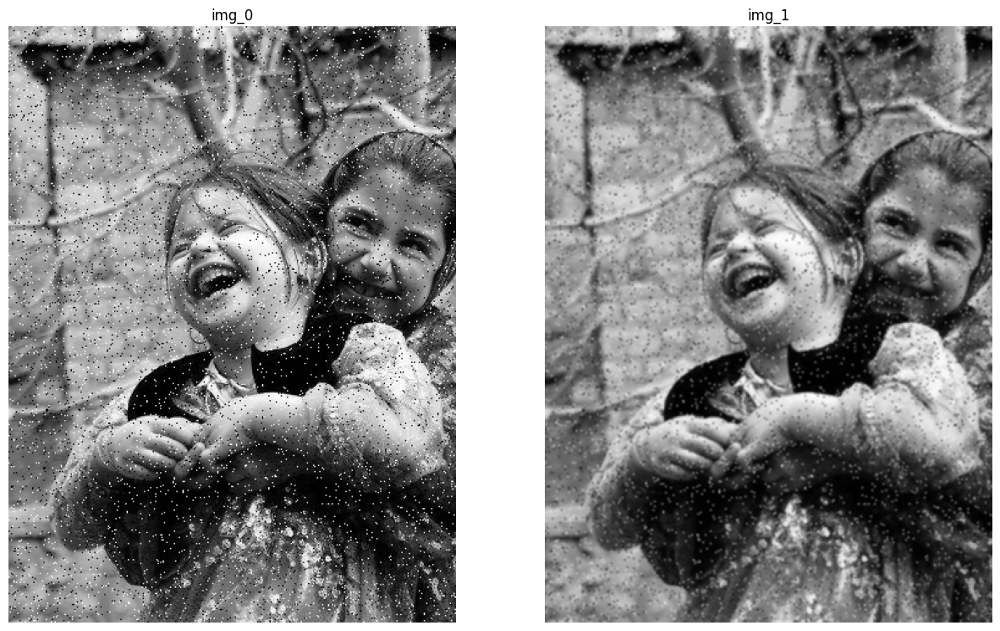

In [98]:
gauss_salpep_img = cv2.GaussianBlur(salt_pepper_noise_gray_img, (3, 3), 0)
show_mult_img(1, 2, (salt_pepper_noise_gray_img, gauss_salpep_img))

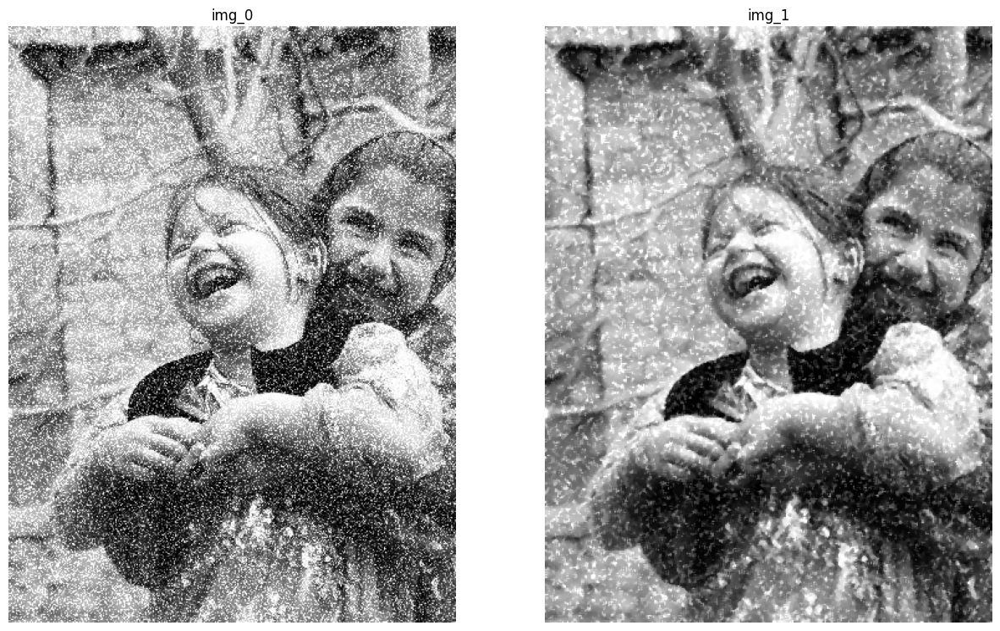

In [99]:
#Median filter
median_gauss_img = cv2.medianBlur(gaus_noise_gray_img, 3)
show_mult_img(1, 2, (gaus_noise_gray_img, median_gauss_img))

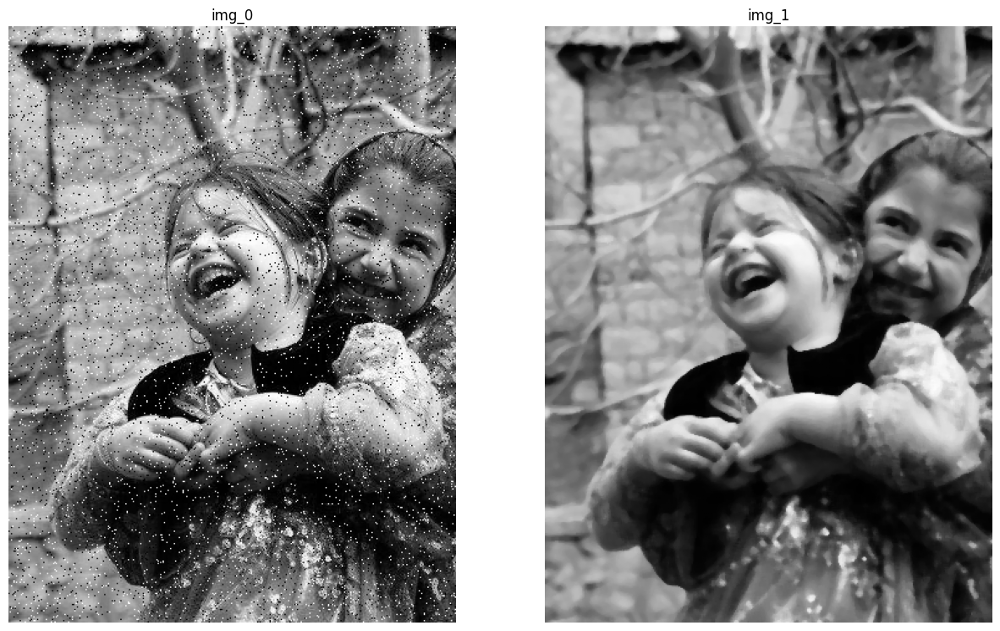

In [100]:
median_salpep_img = cv2.medianBlur(salt_pepper_noise_gray_img, 5)
show_mult_img(1, 2, (salt_pepper_noise_gray_img, median_salpep_img))

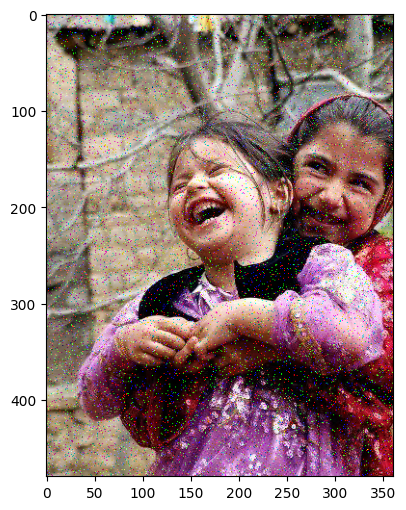

In [102]:
#Color Image
r, g, b = cv2.split(image_color)
r = add_salt_pepper_noise(r, 0.05)
g = add_salt_pepper_noise(g, 0.05)
b = add_salt_pepper_noise(b, 0.05)
noisy_image = cv2.merge((r, g, b))
show_img_plt(noisy_image)

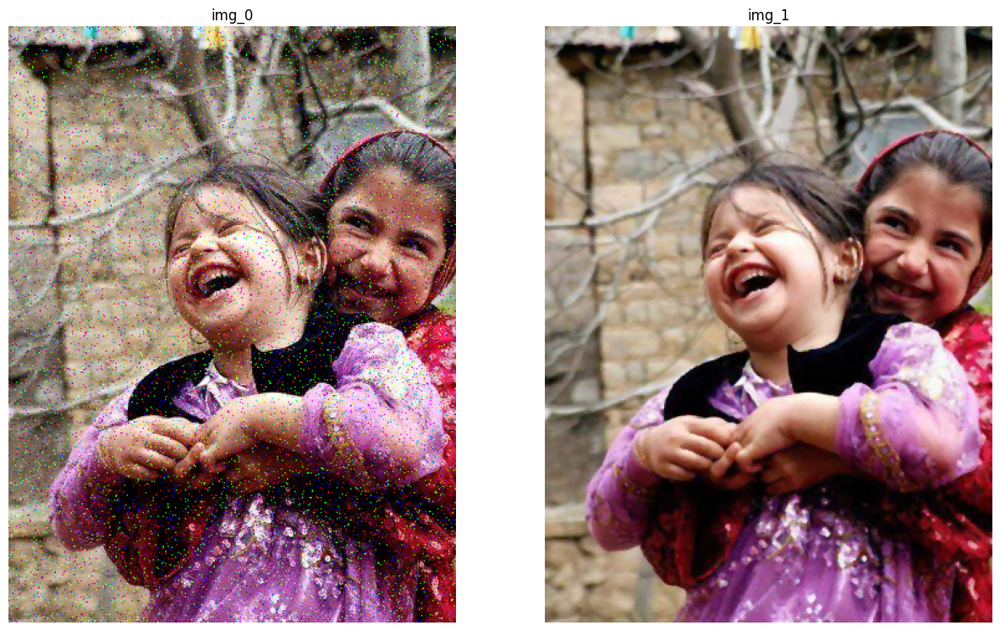

In [103]:
medianimage = cv2.medianBlur(noisy_image, 3)
show_mult_img(1, 2, (noisy_image, medianimage))